In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Eigenvectors1,Inside0,Inside1,Solution0
0,[3.57133534-5.88321392e-09j 3.57133534-5.11344...,(0.001952148928381106+0.0006229137872999604j),(0.0003767909206777746+0.0003771851572618209j),-0.1845,-1.9885,(-7.850970332877742e-06-1.517240799523529e-06j)
1,NaN,(0.0020103759328010643+0.0006771741357248964j),(0.00014414515255735394+0.0003598501872999947j),-0.1640,-1.9885,(-1.2574919596981712e-05-2.411669848571943e-06j)
2,NaN,(0.0021628087128852734+0.000731958844109252j),(-6.878221212656098e-05+0.0003698498500966598j),-0.1435,-1.9885,(-1.6726285066557682e-05-3.341358365014063e-06j)
3,NaN,(0.0022834984595320957+0.0007629795976885772j),(-0.0001868890831201262+0.00038994688706270157j),-0.1230,-1.9885,(-2.029891648030956e-05-4.27141538002725e-06j)
4,NaN,(0.00251609698371616+0.000812113829307711j),(-0.0003824601288965456+0.0004463419217737778j),-0.1025,-1.9885,(-2.326223326901307e-05-5.254172331201339e-06j)
...,...,...,...,...,...,...
28060,NaN,NaN,NaN,0.1025,1.9885,(2.3337867676218022e-05+5.532773792736958e-06j)
28061,NaN,NaN,NaN,0.1230,1.9885,(2.0405696004086564e-05+4.212250279966558e-06j)
28062,NaN,NaN,NaN,0.1435,1.9885,(1.6872887529508732e-05+2.9453279760164285e-06j)
28063,NaN,NaN,NaN,0.1640,1.9885,(1.2736243755318889e-05+1.7916298823402257e-06j)


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([55,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

a_big_ell = 2
b_big_ell = 2
xm_big_ell = 0
ym_big_ell = 0
rot_big_ell = 0
n_ellipses = 6
n_ellipses_single = 3

# Parameters for the inner ellpses
a_small_ell = 0.1
b_small_ell = 0.4
distance_small_ell = 1.1
angles_small_ell = np.linspace(0,2*np.pi, n_ellipses, endpoint=False)
xm_small_ell = distance_small_ell*np.cos(angles_small_ell)
ym_small_ell = distance_small_ell*np.sin(angles_small_ell)
rot_small_ell = angles_small_ell

# Parameters for the inner hypotrochoid
xa_hyp = 0.6
xi_hyp = 0.5
A_hyp = n_ellipses + n_ellipses_single
r_hyp = (xa_hyp+xi_hyp)/(2*(A_hyp-1))
R_hyp = A_hyp*r_hyp
a_hyp = (A_hyp-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
xm_hyp = 0
ym_hyp = 0
rot_hyp = 0

vi, collocation_nodes = geo.create_6_ellipses(a_big_ell,b_big_ell,0,0,0,a_small_ell,b_small_ell,distance_small_ell,n_ellipses,n[0],alpha)


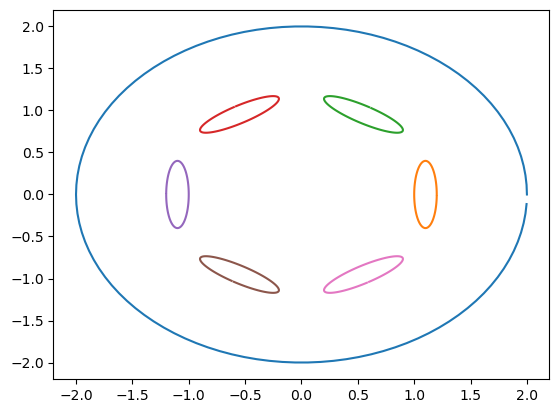

In [7]:
for i in range(n_ellipses+1):
    plt.plot(vi[i][0,:], vi[i][1,:])

In [8]:
vi_closed_curve = np.dstack((vi,vi[:,:,0:1]))

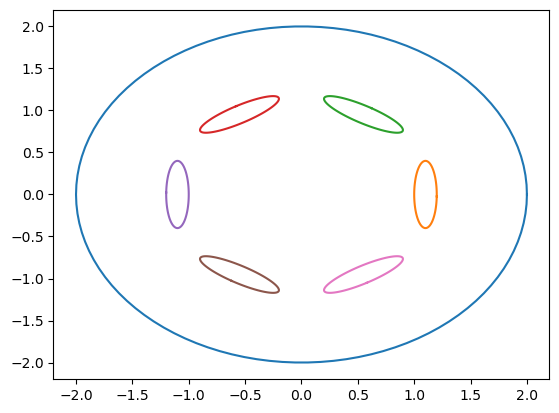

In [9]:
for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:])

In [10]:
def ray_tracing_in_holes(boundary, xmid, ymid, radius):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    xmid : numpy.ndarray
        x-Positions of all points that should be checked to be inside the given domain without holes.
    ymid : numpy.ndarray
        y-Positions of all points that should be checked to be inside the given domain without holes.
    radius : float
        Adds or subtracts a margin around a path to make the enclosed area slightly larger or smaller.

    Returns
    -------
    inside_any : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh,radius=radius) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [11]:
# first eigenvalue

In [12]:
(2.258058605429776-1.4790391134056335e-10j)*(2.258058605429776-1.4790391134056335e-10j)

(5.098828665555466-6.679513995585635e-10j)

In [13]:
# second eigenvalue

In [14]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'[3.57133534-5.88321392e-09j 3.57133534-5.11344056e-09j]'

In [15]:
(3.57133534-5.88321392e-09j) * (3.57133534-5.88321392e-09j)

(12.754436110732916-4.2021859570551866e-08j)

In [16]:
(3.57133534-5.11344056e-09j)*(3.57133534-5.11344056e-09j)

(12.754436110732916-3.652362196183478e-08j)

In [17]:
# third eigenvalue

In [18]:
(3.76408946-1.74493478e-07j) * (3.76408946-1.74493478e-07j)

(14.168369462883062-1.3136181227570839e-06j)

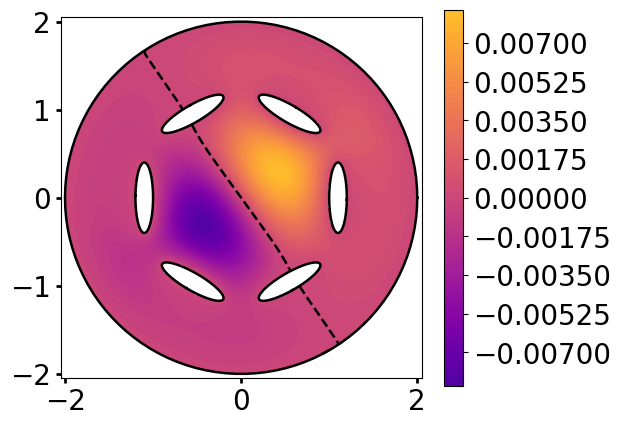

In [23]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
x_boundary = x_inside[triang.triangles]
y_boundary = y_inside[triang.triangles]
x_boundary_flatten = x_boundary.flatten()
y_boundary_flatten = y_boundary.flatten()
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)

mask1_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), x_boundary_flatten, y_boundary_flatten, 0.002)
mask2_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), x_boundary_flatten, y_boundary_flatten, -0.002)
mask3_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), x_boundary_flatten, y_boundary_flatten, -0.002)
mask4_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), x_boundary_flatten, y_boundary_flatten, -0.002)
mask5_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), x_boundary_flatten, y_boundary_flatten, -0.002)
mask6_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), x_boundary_flatten, y_boundary_flatten, -0.002)
mask7_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), x_boundary_flatten, y_boundary_flatten, -0.002)

mask1_reshape = mask1_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask2_reshape = mask2_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask3_reshape = mask3_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask4_reshape = mask4_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask5_reshape = mask5_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask6_reshape = mask6_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask7_reshape = mask7_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask1_boundary = mask1_reshape.any(axis=0)
mask2_boundary = mask2_reshape.any(axis=0)
mask3_boundary = mask3_reshape.any(axis=0)
mask4_boundary = mask4_reshape.any(axis=0)
mask5_boundary = mask5_reshape.any(axis=0)
mask6_boundary = mask6_reshape.any(axis=0)
mask7_boundary = mask7_reshape.any(axis=0)

mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.002)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.002)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.002)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.002)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.002)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.002)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, -0.002)

mask1_inv = ~mask1
mask1_inv_boundary = ~mask1_boundary
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask1_inv_boundary |  mask2_boundary | mask3_boundary | mask4_boundary | mask5_boundary | mask6_boundary | mask7_boundary
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 70, vmin=vmin_sol, vmax=vmax_sol)
cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.axis('square')

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)
for i in range(7):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)
plt.tight_layout()
plt.savefig('circle_six_ellipses_start_result_lower_resolution.eps', format="eps")
plt.show()